# 05- Aprendizaje no supervisado (Clustering)

**Proyecto Final Machine Learning**  
Adriana Lorenzo Mingorance

En este notebook vamos a aplicar técnicas de aprendizaje no supervisado, buscando descubrir estructuras relevantes en los datos.

Para ello, aplicamos K-means como algoritmo de clustering, apoyándonos en técnicas como la reducción de la dimensionalidad (PCA) para facilitar la visualización e interpretación de los resultados.

Así, el análisis se centra en:
-identificar grupos de estudiantes con características similares,
-interpretar los perdiels obtenidos,
-y analizar su relación con la situación académica real (abandono, graduación, etc).

Con este enfoque extraemos información útil para interpretar mejor el fenómeno del abandono y del éxito académico

# 0. Imports

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 
from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score, davies_bouldin_score


## 1. Carga y selección de variables

In [4]:
df = pd.read_csv('../data/rendimiento_estudiantes.csv', sep=';')
objetivo_real = df['objetivo'].copy() #guardamos para comparar al final

print(f"Dataset completo: {df.shape}")

Dataset completo: (4424, 37)


Para clustering usamos el dataset completo (sin split train/test) y seleccionamos variables interpretables y no redundantes

In [7]:
#seleccion de variables para clustering

vars_cluster = [
    #rendimiento académico
    'nota_media_1sem', 'nota_media_2sem', 
    'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas',
    #acceso y contexto previo
    'nota_admision',
    'nota_cualificacion_previa',
    'edad_al_matricularse',
    #situación administrativa
    'matricula_al_dia',
    'deudor',
    'becado'
]

print('Variables seleccionadas para clustering: ')
for v in vars_cluster:
    print(f' - {v}')

Variables seleccionadas para clustering: 
 - nota_media_1sem
 - nota_media_2sem
 - asignaturas_1sem_aprobadas
 - asignaturas_2sem_aprobadas
 - nota_admision
 - nota_cualificacion_previa
 - edad_al_matricularse
 - matricula_al_dia
 - deudor
 - becado


Seleccionamos estas variables porque describen al estudiante de forma estable y no redundante. 
De igual manera, excluimos variables muy correlacionadas entre sí (por ejemplo, evaluadas y aprobadas), y variables macroeconómicas (ya que no describen al individuo)

In [8]:
df_c = df[vars_cluster].copy()

#codificamos variables binarias si son texto
for col in ['matricula_al_dia', 'deudor', 'becado']:
    if df_c[col].dtype == object:
        df_c[col] = (df_c[col].str.lower().str.strip() == 'si').astype(int)

#escalado
scaler = StandardScaler()
X_sc = scaler.fit_transform(df_c)

print(f'Shape final para clustering: {X_sc.shape}')
print(f'Nulos: {df_c.isnull().sum().sum()}')

Shape final para clustering: (4424, 10)
Nulos: 0


## 2. PCA para entender la varianza

Aplicamos PCA para reducir la dimensionalidad, analizar la varianza explicada y obtener una representqación en dos dimensiones

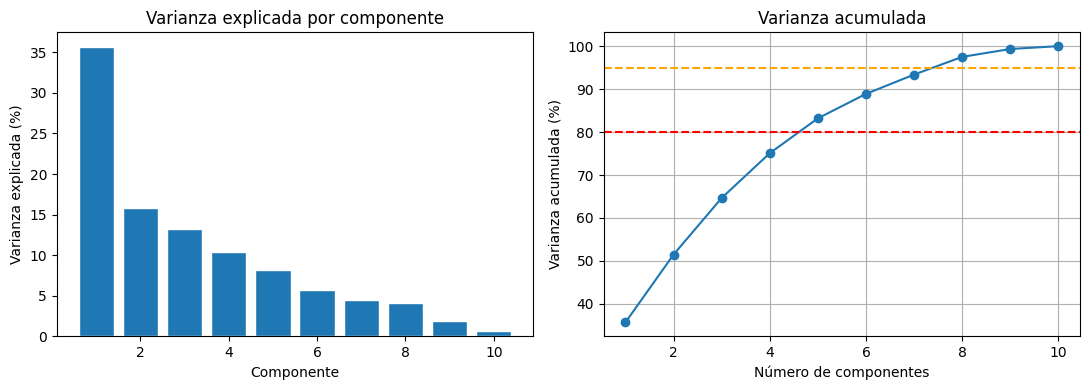

Componentes para explicar 80% de la varianza: 5
Componentes para explicar 95% de la varianza: 8


In [14]:
pca_full = PCA(random_state=42)
pca_full.fit(X_sc)

varianza = pca_full.explained_variance_ratio_ * 100
varianza_acum = np.cumsum(varianza)

fog, axes = plt.subplots(1, 2, figsize=(11, 4))

#varianza por componente
axes[0].bar(range(1, len(varianza)+1), varianza, edgecolor='white')
axes[0].set_title('Varianza explicada por componente')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Varianza explicada (%)')


#varianza acumulada
axes[1].plot(range(1, len(varianza_acum)+1), varianza_acum, marker='o')
axes[1].axhline(80, color='red', linestyle='--')
axes[1].axhline(95, color='orange', linestyle='--')
axes[1].set_title('Varianza acumulada')
axes[1].set_xlabel('Número de componentes')
axes[1].set_ylabel('Varianza acumulada (%)')

plt.tight_layout()
plt.grid()
plt.savefig('../figuras/pca_varianza.png')
plt.show()

n_80 = np.argmax(varianza_acum >= 80) +1
n_95 = np.argmax(varianza_acum >= 95) +1

print(f'Componentes para explicar 80% de la varianza: {n_80}')
print(f'Componentes para explicar 95% de la varianza: {n_95}')